In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [22]:
df=pd.read_csv("/content/ObesityDataSet_raw_and_data_sinthetic.csv")
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

In [24]:
df.isna().sum()


,0
Gender,0
Age,0
Height,0
Weight,0
family_history_with_overweight,0
FAVC,0
FCVC,0
NCP,0
CAEC,0
SMOKE,0


In [25]:
df.duplicated().sum()

np.int64(24)

In [26]:
df.drop_duplicates(inplace=True)

In [27]:
df.duplicated().sum()

np.int64(0)

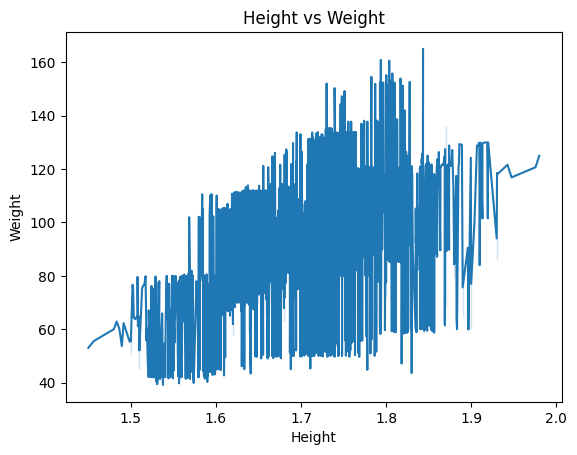

In [28]:
sns.lineplot(x='Height',y='Weight',data=df)
x_label='Height'
y_label='Weight'
plt.title('Height vs Weight')
plt.xlabel(x_label)
plt.ylabel(y_label)
plt.show()

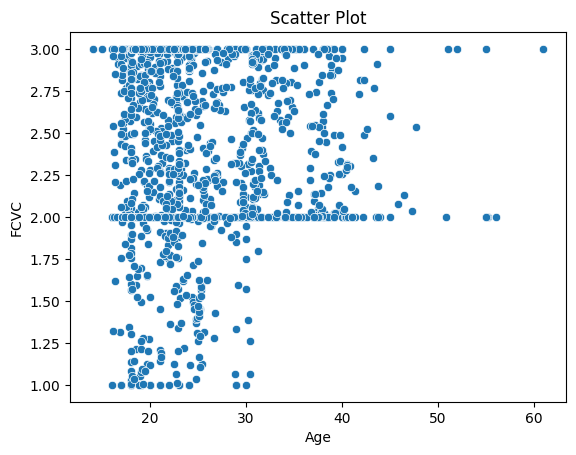

In [29]:
sns.scatterplot(x="Age",y="FCVC",data=df)
plt.title("Scatter Plot")
plt.xlabel("Age")
plt.ylabel("FCVC")
plt.show()

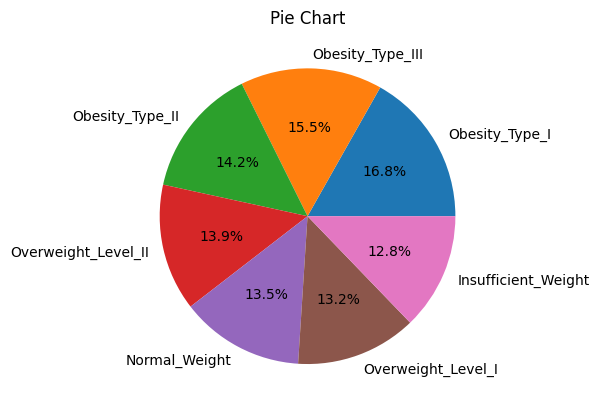

In [30]:
plt.pie(df['NObeyesdad'].value_counts(),labels=df['NObeyesdad'].value_counts().index,autopct='%1.1f%%')
plt.title('Pie Chart')
plt.show()

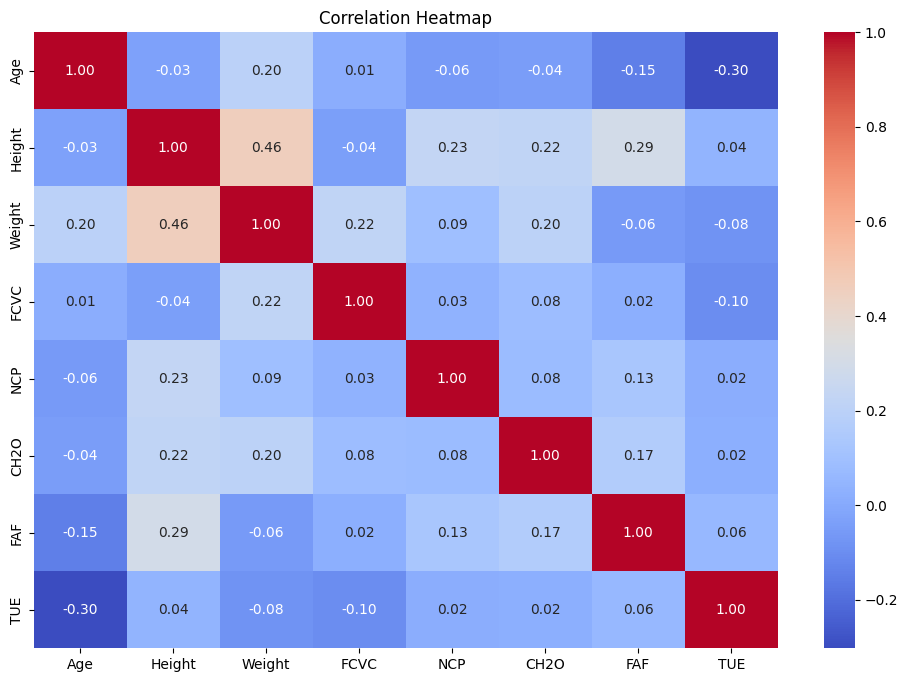

In [31]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [32]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

df['Gender'] = le.fit_transform(df['Gender'])
df['family_history_with_overweight'] = le.fit_transform(df['family_history_with_overweight'])
df['FAVC'] = le.fit_transform(df['FAVC'])
df['CAEC'] = le.fit_transform(df['CAEC'])
df['SMOKE'] = le.fit_transform(df['SMOKE'])
df['SCC'] = le.fit_transform(df['SCC'])
df['CALC'] = le.fit_transform(df['CALC'])
df['MTRANS'] = le.fit_transform(df['MTRANS'])
df['NObeyesdad'] = le.fit_transform(df['NObeyesdad'])


x = df.iloc[:, :-1]
y = df.iloc[:, -1]


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [33]:
scaler=StandardScaler()
scaler.fit(x_train)
x_train=scaler.transform(x_train)
x_test=scaler.transform(x_test)
print(x_train)
print(x_test)

[[ 0.98159534 -0.52747999  1.14792441 ... -1.09030512  1.42960449
   0.50593989]
 [ 0.98159534 -0.99682251  0.89689452 ...  0.56104507 -0.51024095
   0.50593989]
 [ 0.98159534 -0.30900043  1.78622423 ... -1.08971889 -0.51024095
  -1.86823165]
 ...
 [ 0.98159534 -0.23295849  0.96918361 ...  1.1650974  -0.51024095
   0.50593989]
 [ 0.98159534 -0.17745968  0.61877647 ...  2.17613655  1.42960449
   0.50593989]
 [-1.01874974 -1.03105588 -1.12022278 ... -0.81605549 -0.51024095
   0.50593989]]
[[-1.01874974 -0.90240706 -0.2376003  ...  0.56104507 -0.51024095
   0.50593989]
 [ 0.98159534  1.06816894  1.56747764 ... -0.73091848 -0.51024095
   0.50593989]
 [-1.01874974 -1.30971752 -1.01221577 ... -1.09030512  1.42960449
   0.50593989]
 ...
 [ 0.98159534  0.17541596  0.71723566 ... -1.00287934 -0.51024095
   0.50593989]
 [ 0.98159534  1.95061109  0.42265734 ... -1.09030512  1.42960449
  -1.86823165]
 [-1.01874974  0.25475753 -0.58018774 ... -1.09030512  1.42960449
   1.2973304 ]]


In [34]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(x_train, y_train)

RandomForestClassifier(random_state=42)

In [35]:
rf_pred=model.predict(x_test)
print("Actual:", y_test.values.tolist())
print("Predict:", rf_pred.tolist())
print("Accuracy:",accuracy_score(y_test,rf_pred))

Actual: [2, 3, 5, 0, 3, 5, 6, 4, 0, 1, 3, 2, 4, 1, 6, 5, 5, 3, 6, 5, 4, 5, 1, 0, 2, 2, 0, 0, 0, 2, 1, 1, 2, 3, 6, 4, 1, 1, 0, 1, 1, 2, 5, 4, 1, 5, 3, 5, 1, 4, 6, 0, 2, 4, 4, 4, 5, 2, 6, 5, 6, 2, 1, 3, 1, 3, 2, 5, 6, 2, 6, 1, 2, 1, 2, 0, 3, 1, 0, 0, 5, 5, 4, 2, 0, 0, 3, 6, 1, 2, 3, 3, 3, 3, 2, 3, 2, 4, 6, 4, 1, 6, 2, 6, 1, 1, 0, 5, 4, 2, 1, 3, 2, 0, 4, 3, 5, 3, 1, 3, 0, 5, 2, 0, 5, 4, 5, 1, 5, 5, 3, 0, 6, 2, 5, 2, 6, 1, 5, 5, 4, 5, 5, 1, 4, 1, 5, 4, 4, 6, 0, 4, 4, 2, 0, 3, 0, 4, 4, 2, 1, 3, 3, 0, 3, 1, 1, 4, 6, 0, 2, 0, 3, 5, 0, 6, 6, 2, 6, 1, 0, 1, 3, 3, 0, 6, 1, 3, 6, 2, 3, 3, 2, 1, 4, 1, 2, 5, 6, 1, 2, 4, 2, 5, 6, 2, 2, 6, 5, 2, 1, 3, 3, 6, 3, 3, 4, 4, 6, 4, 2, 0, 5, 4, 2, 3, 5, 4, 6, 5, 2, 6, 1, 5, 0, 3, 6, 4, 2, 3, 0, 6, 4, 5, 3, 1, 1, 5, 3, 4, 6, 4, 1, 1, 2, 0, 4, 1, 4, 2, 2, 5, 3, 4, 2, 5, 1, 0, 2, 4, 0, 4, 3, 3, 1, 2, 6, 3, 1, 1, 6, 6, 2, 5, 2, 1, 3, 4, 3, 0, 5, 2, 2, 6, 2, 1, 1, 4, 0, 5, 2, 0, 0, 0, 1, 3, 3, 3, 0, 5, 4, 0, 4, 6, 4, 1, 1, 0, 5, 3, 6, 1, 2, 2, 0, 4, 2, 0, 0, 4, 0

In [36]:
print(classification_report(y_test,rf_pred))

              precision    recall  f1-score   support

           0       0.98      0.93      0.96        59
           1       0.84      0.97      0.90        61
           2       1.00      0.94      0.97        70
           3       1.00      1.00      1.00        64
           4       1.00      1.00      1.00        60
           5       0.98      0.89      0.93        55
           6       0.90      0.96      0.93        49

    accuracy                           0.96       418
   macro avg       0.96      0.96      0.96       418
weighted avg       0.96      0.96      0.96       418



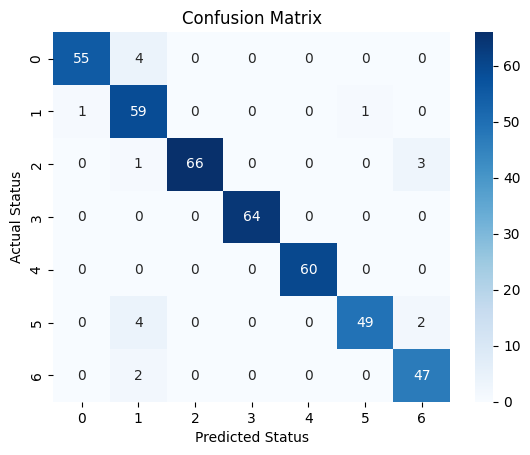

In [40]:
cm = confusion_matrix(y_test, rf_pred, labels=model.classes_)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.show()

In [37]:
new_data=[[1,23,1.72,85,1,1,2,3,2,0,2,0,1,1,1,3]]
prediction=model.predict(new_data)
print(prediction)

[3]
